In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/metadata.csv
/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv


## 📦 Cell: Load All Libraries

> **What is happening:** We import every Python tool needed for this entire notebook in one place — opening our full toolbox before starting work.

**🔑 Key observations:**
- Same libraries as v16: LightGBM (×2 with different seeds) + CatBoost. XGBoost remains removed (was getting 0% blend weight since v15).
- `SEED = 42` — the "magic number" that makes all random operations reproducible.
- Two LightGBM seeds (42 and 123) create model diversity for a better ensemble.

**Expected output:**
```
ALL LIBRARIES LOADED OK.
NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).
```


In [2]:
import subprocess, sys
try:
    import catboost
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "catboost", "-q"], check=True)

import numpy as np
import pandas as pd
import warnings
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.2f}'.format)

from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score
import lightgbm as lgb
from catboost import CatBoostRegressor

SEED = 42
np.random.seed(SEED)
print("ALL LIBRARIES LOADED OK.")
print("NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).")


ALL LIBRARIES LOADED OK.
NOTE: XGBoost removed in v15 (was getting 0 percent blend weight).


## 🛠️ Cell: Helper Functions (RMSLE + Submission Saver)

> **What is happening:** Two reusable functions defined here and used throughout the notebook.

**🔑 Key observations:**
- `rmsle()` computes the competition metric — log-scale comparison so $1K error on $10K machine = same penalty as $10K error on $100K machine.
- `np.maximum(y_pred, 0)` ensures no negative price predictions.
- `make_submission()` saves final predictions to `submission.csv`.

**Expected output:** `Helper functions ready.`


In [3]:
def rmsle(y_true, y_pred):
    y_pred = np.maximum(y_pred, 0)
    return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(y_pred)))

def make_submission(preds, ids, filename='submission.csv'):
    preds = np.maximum(preds, 0)
    sub = pd.DataFrame({'TransactionID': ids, 'TargetValue': preds})
    sub.to_csv(filename, index=False)
    print(f'Saved {filename}: {len(sub):,} rows | '
          f'min=${sub["TargetValue"].min():,.0f} '
          f'median=${sub["TargetValue"].median():,.0f} '
          f'max=${sub["TargetValue"].max():,.0f}')
    return sub

print("Helper functions ready.")

Helper functions ready.


## 📂 Cell: Load Competition Data

> **What is happening:** Reads all competition CSV files from Kaggle's cloud storage into memory.

**🔑 Key observations:**
- Train: 138,701 rows × 50 cols (has actual price `TargetValue`)
- Test: 15,000 rows × 49 cols (no price — we must predict it!)
- Price range: $7,500–$142,000 (wide range → use log-transform during training)

**Expected output:**
```
TRAIN :  138,701 rows x 50 cols
TEST  :   15,000 rows x 49 cols
Price range: $7,500 - $142,000
```


In [4]:
train_df = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/train.csv', low_memory=False)
test_df  = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/test.csv',  low_memory=False)
sample   = pd.read_csv('/kaggle/input/competitions/heavy-equipment-selling-price-prediction-challenge/sample_submission.csv')

print("=" * 55)
print(f"TRAIN : {train_df.shape[0]:>8,} rows x {train_df.shape[1]} cols")
print(f"TEST  : {test_df.shape[0]:>8,} rows x {test_df.shape[1]} cols")
print("=" * 55)
t = train_df['TargetValue']
print(f"Price range: ${t.min():,.0f} - ${t.max():,.0f}")

TRAIN :  138,701 rows x 50 cols
TEST  :   15,000 rows x 49 cols
Price range: $7,500 - $142,000


## ⏳ Cell: Leak-Free Asset History Features

> **What is happening:** Computes historical sale features for machines that have been sold multiple times. Uses strict time ordering to prevent future data from leaking into training.

**🔑 Key observations:**
- Only 14.4% of machines (19,969 rows) have prior sale history.
- `shift(1)` ensures we always look at the PREVIOUS row, never the current one.
- `Has_Asset_History` binary flag: 1 = machine has history, 0 = first sale (carried from v16).

| Feature | What it captures |
|---|---|
| Asset_Prev_Sales_Count | How many times sold before |
| Has_Asset_History | Was this machine sold before? (1/0) |
| Asset_Prev_Mean_Price | Average of all previous prices |
| Asset_Prev_Last_Price | Most recent previous price |
| Asset_Days_Since_Last_Sale | Days since last auction |

**Expected output:**
```
Building leak-free asset history features...
Asset history features added. Train: (138701, 55) | Test: (15000, 55)
Rows with prior history: 19,969 / 138,701 (14.4%)
```


In [5]:
print("Building leak-free asset history features...")
full_df = pd.concat([train_df, test_df], axis=0, ignore_index=True)
full_df = full_df.sort_values('TransactionID').reset_index(drop=True)

full_df['log_target'] = np.log1p(full_df['TargetValue'])
grouped = full_df.groupby('AssetID')

full_df['Asset_Prev_Sales_Count'] = grouped.cumcount().astype(np.int32)
full_df['Has_Asset_History']      = (full_df['Asset_Prev_Sales_Count'] > 0).astype(np.int8)

full_df['cum_sum_log_target']      = grouped['log_target'].cumsum()
full_df['cum_sum_log_target_prev'] = full_df['cum_sum_log_target'] - full_df['log_target'].fillna(0)
full_df['has_target']              = full_df['TargetValue'].notna().astype(np.int32)
full_df['cum_count_target']        = grouped['has_target'].cumsum()
full_df['cum_count_target_prev']   = full_df['cum_count_target'] - full_df['has_target']

full_df['Asset_Prev_Mean_Price'] = (
    full_df['cum_sum_log_target_prev'] /
    full_df['cum_count_target_prev'].replace(0, np.nan)
).astype(np.float32)
full_df['Asset_Prev_Last_Price'] = grouped['log_target'].shift(1).astype(np.float32)

full_df['TransactionDate_dt'] = pd.to_datetime(full_df['TransactionDate'], errors='coerce')
full_df['Asset_Days_Since_Last_Sale'] = (
    grouped['TransactionDate_dt'].diff().dt.days.astype(np.float32)
)

full_df = full_df.drop(columns=[
    'log_target', 'cum_sum_log_target', 'cum_sum_log_target_prev',
    'has_target', 'cum_count_target', 'cum_count_target_prev', 'TransactionDate_dt'
])

train_features = full_df[full_df['TargetValue'].notna()].copy()
test_features  = full_df[full_df['TargetValue'].isna()].copy()

train_features = (train_features.set_index('TransactionID')
                  .loc[train_df['TransactionID']].reset_index())
test_features  = (test_features.set_index('TransactionID')
                  .loc[test_df['TransactionID']].reset_index())

n_hist = train_features['Has_Asset_History'].sum()
print(f"Asset history features added. Train: {train_features.shape} | Test: {test_features.shape}")
print(f"Rows with prior history: {n_hist:,} / {len(train_features):,} ({n_hist/len(train_features)*100:.1f}%)")


Building leak-free asset history features...
Asset history features added. Train: (138701, 55) | Test: (15000, 55)
Rows with prior history: 19,969 / 138,701 (14.4%)


## 🔨 Cell: Base Feature Engineering (`preprocess_df`)

> **What is happening:** Transforms raw data into meaningful numbers. v17 adds 4 new features based on v16's feature importance rankings.

**🔑 Key observations:**

**🆕 NEW in v17 #1 — SaleDay Cyclical Encoding:**
```python
df['SaleDay_sin'] = np.sin(2 * np.pi * df['SaleDay'] / 31)
df['SaleDay_cos'] = np.cos(2 * np.pi * df['SaleDay'] / 31)
```
SaleDay was the **#3 most important feature** in v16 without cyclical encoding! The problem: Day 31 and Day 1 are numerically far (30 apart) but temporally adjacent (end-of-month → start-next-month). Cyclical encoding fixes this by wrapping days into a circle.

**🆕 NEW in v17 #2 — LogHours × LogAge Interaction:**
```python
df['LogHours_x_LogAge'] = df['LogHours'] * df['LogAge'].fillna(0)
```
5,000 hours on a 3-year-old machine = extreme wear. Same 5,000 hours on a 20-year-old machine = normal. This product feature captures usage intensity relative to age.

**🆕 NEW in v17 #3 — Years_Since_2000 Market Trend:**
```python
df['Years_Since_2000'] = (df['SaleYear'] - 2000).clip(lower=-10, upper=20)
```
Equipment prices changed dramatically over 2000-2015 (2008 recession dip, recovery). A linear market trend feature captures this.

**🆕 NEW in v17 #4 — Hours Outlier Clipping:**
```python
hours_99 = df['OperationalHoursMeter'].quantile(0.99)
df['OperationalHoursMeter'] = df['OperationalHoursMeter'].clip(upper=hours_99)
```
Removes extreme outlier meter readings (40,000+ hours) that mislead the model.

**Expected output:**
```
Preprocessing features (no leaky group features)...
Train preprocessed: (138701, 84) | Test preprocessed: (15000, 84)
```


In [6]:
def preprocess_df(df):
    """
    BASE preprocessing only - no leaky group/frequency features.
    v17 additions vs v16:
      - SaleDay cyclical sin/cos (SaleDay was #3 feature in v16 with no cyclical!)
      - LogHours x LogAge interaction (usage intensity in context of age)
      - Years_Since_2000 numeric market time trend
    """
    df = df.copy()
    df['ProductConfigID'] = df['ProductConfigID'].astype(str)

    # ── Date features ────────────────────────────────────────────────────────
    df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors='coerce')
    df['SaleYear']        = df['TransactionDate'].dt.year
    df['SaleMonth']       = df['TransactionDate'].dt.month
    df['SaleDay']         = df['TransactionDate'].dt.day
    df['SaleDayOfWeek']   = df['TransactionDate'].dt.dayofweek
    df['SaleDayOfYear']   = df['TransactionDate'].dt.dayofyear
    df['SaleQuarter']     = df['TransactionDate'].dt.quarter
    df['SaleWeek']        = df['TransactionDate'].dt.isocalendar().week.astype(int)

    # Cyclical encoding for SaleDayOfYear (top feature in v15/v16)
    df['SaleDayOfYear_sin'] = np.sin(2*np.pi*df['SaleDayOfYear']/365).astype(np.float32)
    df['SaleDayOfYear_cos'] = np.cos(2*np.pi*df['SaleDayOfYear']/365).astype(np.float32)

    # Cyclical encoding for SaleMonth
    df['SaleMonth_sin'] = np.sin(2*np.pi*df['SaleMonth']/12).astype(np.float32)
    df['SaleMonth_cos'] = np.cos(2*np.pi*df['SaleMonth']/12).astype(np.float32)

    # Cyclical encoding for SaleDayOfWeek
    df['SaleDayOfWeek_sin'] = np.sin(2*np.pi*df['SaleDayOfWeek']/7).astype(np.float32)
    df['SaleDayOfWeek_cos'] = np.cos(2*np.pi*df['SaleDayOfWeek']/7).astype(np.float32)

    # NEW v17: Cyclical encoding for SaleDay (day of month, was #3 feature!)
    # SaleDay range: 1-31. Day 31 and Day 1 are adjacent (end-of-month effects)
    df['SaleDay_sin'] = np.sin(2*np.pi*df['SaleDay']/31).astype(np.float32)
    df['SaleDay_cos'] = np.cos(2*np.pi*df['SaleDay']/31).astype(np.float32)

    # NEW v17: Simple market time trend feature
    # Captures overall market price trend relative to year 2000
    df['Years_Since_2000'] = (df['SaleYear'] - 2000).clip(lower=-10, upper=20).astype(np.float32)

    # Time-based flags
    df['IsMonthEnd']    = df['TransactionDate'].dt.is_month_end.astype(np.int8)
    df['IsMonthStart']  = df['TransactionDate'].dt.is_month_start.astype(np.int8)
    df['IsQuarterEnd']  = df['TransactionDate'].dt.is_quarter_end.astype(np.int8)
    df['IsQuarterStart']= df['TransactionDate'].dt.is_quarter_start.astype(np.int8)
    df['IsYearEnd']     = df['TransactionDate'].dt.is_year_end.astype(np.int8)
    df['IsYearStart']   = df['TransactionDate'].dt.is_year_start.astype(np.int8)
    df = df.drop(columns=['TransactionDate'])

    # ── ManufactureYear cleaning ─────────────────────────────────────────────
    df.loc[df['ManufactureYear'] <= 1920, 'ManufactureYear'] = np.nan

    # ── OperationalHoursMeter: 0 = missing ──────────────────────────────────
    df.loc[df['OperationalHoursMeter'] == 0, 'OperationalHoursMeter'] = np.nan

    # ── Machine Age ──────────────────────────────────────────────────────────
    df['MachineAge']    = (df['SaleYear'] - df['ManufactureYear']).clip(lower=0)
    df['MachineAge_sq'] = (df['MachineAge'] ** 2).astype(np.float32)
    df['LogAge']        = np.log1p(df['MachineAge']).astype(np.float32)

    # ── Ordinal encodings ────────────────────────────────────────────────────
    tier_map  = {'Low': 0, 'Medium': 1, 'High': 2}
    scale_map = {'Mini': 0, 'Compact': 1, 'Small': 2, 'Medium': 3, 'Large / Medium': 4, 'Large': 5}
    df['UtilizationTierOrd'] = df['UtilizationTier'].map(tier_map)
    df['AssetScaleOrd']      = df['AssetScaleFactor'].map(scale_map)

    # ── Hours engineering ────────────────────────────────────────────────────
    hours_99 = df['OperationalHoursMeter'].quantile(0.99)
    df['OperationalHoursMeter'] = df['OperationalHoursMeter'].clip(upper=hours_99)
    df['HoursPresent'] = df['OperationalHoursMeter'].notna().astype(np.int8)
    df['LogHours']     = np.log1p(df['OperationalHoursMeter'].fillna(0))
    df['UsagePerYear'] = df['OperationalHoursMeter'] / (df['MachineAge'] + 1)

    # NEW v17: LogHours x LogAge interaction
    # Captures usage intensity relative to machine age
    # High LogHours on a young machine = heavily used; same hours on old = normal
    df['LogHours_x_LogAge'] = (df['LogHours'] * df['LogAge'].fillna(0)).astype(np.float32)

    # ── Age bucket flags ─────────────────────────────────────────────────────
    df['IsNewMachine'] = (df['MachineAge'] <= 2).astype(np.int8)
    df['IsOldMachine'] = (df['MachineAge'] >= 20).astype(np.int8)
    df['AgeDecade']    = (df['MachineAge'] // 10).fillna(-1).astype(int)

    # ── Clean text and convert to category ──────────────────────────────────
    text_cols = df.select_dtypes(include='object').columns.tolist()
    df[text_cols] = df[text_cols].replace('None or Unspecified', np.nan)
    for col in text_cols:
        df[col] = df[col].fillna('Missing').astype('category')

    # ── Drop noisy columns ───────────────────────────────────────────────────
    for c in ['col18', 'col19', 'UtilizationTier', 'AssetScaleFactor']:
        if c in df.columns:
            df = df.drop(columns=[c])

    return df

print("Preprocessing features (no leaky group features)...")
train_proc = preprocess_df(train_features)
test_proc  = preprocess_df(test_features)
print(f"Train preprocessed: {train_proc.shape} | Test preprocessed: {test_proc.shape}")


Preprocessing features (no leaky group features)...
Train preprocessed: (138701, 84) | Test preprocessed: (15000, 84)


## 📐 Cell: Prepare Feature Matrices

> **What is happening:** Separates data into inputs (X) and log-transformed target (y). Identifies categorical and numerical columns.

**🔑 Key observations:**
- v17 has **41 numerical features** (vs v16's 37) — 4 more from new features.
- `y_all = np.log1p(TargetValue)` — log-transform makes the target more symmetric and easier to model.
- `cat_cols` = list of text/category columns for CatBoost and LightGBM.

**Expected output:**
```
Feature matrix : (138701, 81)
Test matrix    : (15000, 81)
Cat features   : 40
Num features   : 41
```


In [7]:
ID_COLS = ['TransactionID', 'AssetID']

y_all        = np.log1p(train_proc['TargetValue'].values)
X_all        = train_proc.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')
X_test_final = test_proc.drop(columns=ID_COLS + ['TargetValue'], errors='ignore')
test_ids     = test_df['TransactionID'].values
cat_cols     = X_all.select_dtypes(include=['category', 'object']).columns.tolist()

print(f"Feature matrix : {X_all.shape}")
print(f"Test matrix    : {X_test_final.shape}")
print(f"Cat features   : {len(cat_cols)}")
print(f"Num features   : {X_all.shape[1] - len(cat_cols)}")


Feature matrix : (138701, 81)
Test matrix    : (15000, 81)
Cat features   : 40
Num features   : 41


## ⭐ Cell: Fold-Level Feature Engineering Functions

> **What is happening:** Defines THREE functions that MUST only be called inside the CV loop to prevent data leakage.

**🔑 Key observations:**

**Function 1 — OOF Target Encoding (7 columns, UNCHANGED from v16):**
Spec_FullDescriptor, Spec_BaseClass, ProductConfigID, FunctionalClassification, Spec_SubClass, Spec_VariantModifier, RegionCode.

**Function 2 — Interaction TEs (EXPANDED in v17 — now 6!):**

| Interaction | Type | Alpha | Source |
|---|---|---|---|
| InventoryGroupDesc × RegionCode | Region | 20 | v15/v16 |
| FunctionalClass × RegionCode | Region | 22 | v16 |
| Spec_SubClass × RegionCode | Region | 22 | v16 |
| **ProductConfigID × SaleYear** | **Time (NEW!)** | **25** | v17 — eta²=0.8443 |
| **Spec_BaseClass × SaleYear** | **Time (NEW!)** | **25** | v17 — eta²=0.5240 |
| **FunctionalClass × SaleYear** | **Time (NEW!)** | **20** | v17 — eta²=0.3914 |

> **eta²** measures how strongly a combination explains price variance. `ProductConfigID×SaleYear` with eta²=0.8443 means knowing the exact machine model AND when it was sold explains 84% of price variance!

**Function 3 — Group Statistics (UNCHANGED from v16):**
6 grouping columns, 2 target features (Hours, MachineAge), frequency encoding for 4 ID columns.

**Expected output:**
```
All fold-level feature engineering functions compiled. Ready for CV.
Single-column TE : 7 columns
Region interactions (v16 proven): 3
Time interactions (NEW v17): 3
```

**⚠️ Warning:** These functions use training fold data only — calling them on the full dataset would leak target information into features!


In [8]:
# ─── OOF Target Encoding ──────────────────────────────────────────────────────
def add_oof_target_encoding(X_tr, y_tr, X_vl, X_te, cols, n_splits=5, alpha=15.0, seed=42):
    """
    Leak-free OOF target encoding with Bayesian smoothing.
    Train rows encoded from OTHER inner folds (never their own target).
    Val/Test rows encoded from full training fold statistics.
    alpha controls smoothing toward global mean for rare categories.
    """
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()
    global_mean = float(y_tr.mean())
    kf_inner    = KFold(n_splits=n_splits, shuffle=True, random_state=seed)

    for col in cols:
        col_te = col + '_TE'
        X_tr[col_te] = global_mean
        X_vl[col_te] = global_mean
        X_te[col_te] = global_mean

        tr_val = X_tr[col].astype(str)
        vl_val = X_vl[col].astype(str)
        te_val = X_te[col].astype(str)

        stats = pd.DataFrame({'cat': tr_val, 'y': y_tr})
        agg   = stats.groupby('cat')['y'].agg(['mean', 'count'])
        agg['sm'] = (agg['count']*agg['mean'] + alpha*global_mean) / (agg['count'] + alpha)
        m = agg['sm'].to_dict()
        X_vl[col_te] = vl_val.map(m).fillna(global_mean).values
        X_te[col_te] = te_val.map(m).fillna(global_mean).values

        col_idx = X_tr.columns.get_loc(col_te)
        for tr_in, vl_in in kf_inner.split(X_tr):
            in_s = pd.DataFrame({'cat': tr_val.iloc[tr_in], 'y': y_tr[tr_in]})
            in_a = in_s.groupby('cat')['y'].agg(['mean', 'count'])
            in_a['sm'] = (in_a['count']*in_a['mean'] + alpha*global_mean) / (in_a['count'] + alpha)
            X_tr.iloc[vl_in, col_idx] = (
                tr_val.iloc[vl_in].map(in_a['sm'].to_dict()).fillna(global_mean).values
            )
    return X_tr, X_vl, X_te


# ─── Interaction Target Encoding ──────────────────────────────────────────────
def add_interaction_target_encoding(X_tr, y_tr, X_vl, X_te,
                                    col_a, col_b, alpha=22.0, seed=42):
    """
    Creates a combined category (col_a + '__x__' + col_b) and applies OOF TE.
    Higher alpha than single-column TE because interaction cells are sparser.
    col_b can be a string column (category) or numeric (e.g., SaleYear as int/str).
    """
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()
    global_mean = float(y_tr.mean())
    kf_inner    = KFold(n_splits=5, shuffle=True, random_state=seed)
    feat_name   = col_a + '__x__' + col_b + '_TE'

    # Build interaction key: convert both columns to string before concat
    tr_int = X_tr[col_a].astype(str) + '__' + X_tr[col_b].astype(str)
    vl_int = X_vl[col_a].astype(str) + '__' + X_vl[col_b].astype(str)
    te_int = X_te[col_a].astype(str) + '__' + X_te[col_b].astype(str)

    X_tr[feat_name] = global_mean
    X_vl[feat_name] = global_mean
    X_te[feat_name] = global_mean

    stats = pd.DataFrame({'cat': tr_int, 'y': y_tr})
    agg   = stats.groupby('cat')['y'].agg(['mean', 'count'])
    agg['sm'] = (agg['count']*agg['mean'] + alpha*global_mean) / (agg['count'] + alpha)
    m = agg['sm'].to_dict()
    X_vl[feat_name] = vl_int.map(m).fillna(global_mean).values
    X_te[feat_name] = te_int.map(m).fillna(global_mean).values

    col_idx = X_tr.columns.get_loc(feat_name)
    for tr_in, vl_in in kf_inner.split(X_tr):
        in_s = pd.DataFrame({'cat': tr_int.iloc[tr_in], 'y': y_tr[tr_in]})
        in_a = in_s.groupby('cat')['y'].agg(['mean', 'count'])
        in_a['sm'] = (in_a['count']*in_a['mean'] + alpha*global_mean) / (in_a['count'] + alpha)
        X_tr.iloc[vl_in, col_idx] = (
            tr_int.iloc[vl_in].map(in_a['sm'].to_dict()).fillna(global_mean).values
        )
    return X_tr, X_vl, X_te


# ─── Fold-Level Group Statistics ──────────────────────────────────────────────
def add_fold_group_features(X_tr, X_vl, X_te):
    """
    Group-level statistics computed from training fold ONLY, then
    mapped to validation/test. Prevents distribution-mismatch leakage.
    """
    X_tr, X_vl, X_te = X_tr.copy(), X_vl.copy(), X_te.copy()

    # 1. Frequency encoding for high-cardinality columns
    freq_cols = ['ProductConfigID', 'Spec_FullDescriptor', 'Spec_BaseClass', 'VendorPartnerID']
    for col in freq_cols:
        freq_map    = X_tr[col].astype(str).value_counts().to_dict()
        global_freq = 1.0
        for df_part in [X_tr, X_vl, X_te]:
            df_part[col+'_Freq'] = (df_part[col].astype(str)
                                    .map(freq_map).fillna(global_freq)
                                    .astype(np.float32))

    # 2. Group means for Hours and MachineAge per group column
    group_cols   = ['InventoryGroupCategory', 'Spec_BaseClass', 'ProductConfigID',
                    'VendorPartnerID', 'RegionCode', 'FunctionalClassification']
    target_feats = ['OperationalHoursMeter', 'MachineAge']

    for grp_col in group_cols:
        for target_col in target_feats:
            global_mean = float(X_tr[target_col].mean())
            group_means = (X_tr.groupby(X_tr[grp_col].astype(str))[target_col]
                           .mean().to_dict())
            feat_name = f'{grp_col}_{target_col}_mean'
            for df_part in [X_tr, X_vl, X_te]:
                df_part[feat_name] = (
                    df_part[grp_col].astype(str)
                    .map(group_means).fillna(global_mean)
                    .astype(np.float32)
                )
            for df_part in [X_tr, X_vl, X_te]:
                df_part[f'{target_col}_rel_{grp_col}'] = (
                    df_part[target_col] / (df_part[feat_name] + 1)
                ).astype(np.float32)

    return X_tr, X_vl, X_te


# TE columns: same 7 as v16 (all proven effective)
TE_COLS = [
    'Spec_FullDescriptor',       # 3505 unique
    'Spec_BaseClass',            # 1249 unique, eta2=0.43
    'ProductConfigID',           # 3594 unique
    'FunctionalClassification',  # 65 unique, eta2=0.35
    'Spec_SubClass',             # 147 unique, eta2=0.24
    'Spec_VariantModifier',      # 132 unique, eta2=0.22
    'RegionCode',                # 53 unique
]

print("All fold-level feature engineering functions compiled. Ready for CV.")
print(f"Single-column TE : {len(TE_COLS)} columns")
print("Region interactions : 3 (InventoryGroupDesc, FC, Spec_SubClass x Region)")
print("Time interactions   : 3 NEW (ProductConfig, Spec_BaseClass, FC x SaleYear)")


All fold-level feature engineering functions compiled. Ready for CV.
Single-column TE : 7 columns
Region interactions : 3 (InventoryGroupDesc, FC, Spec_SubClass x Region)
Time interactions   : 3 NEW (ProductConfig, Spec_BaseClass, FC x SaleYear)


## 🔄 Cell: 5-Fold Cross Validation Loop (Main Training)

> **What is happening:** The heart of the notebook. Trains 3 models using 5-fold CV, applying all v17 feature engineering inside each fold.

**🔑 Key observations:**

**Model parameters unchanged from v16:**
- LGB1: num_leaves=511, lr=0.010, subsample=0.75, seed=42
- LGB2: num_leaves=511, lr=0.010, subsample=0.80, seed=123
- CatBoost: max_leaves=255, lr=0.010, bagging_temperature=0.5

**What is new inside each fold:**
1. Step 3 now includes 3 new TIME interactions (Product×Year, BaseClass×Year, FC×Year)
2. Total interaction TEs per fold: 6 (up from 3 in v16)

**Fold-by-fold results:**
| Fold | LGB1 | LGB2 | CAT |
|---|---|---|---|
| 1 | 0.19347 (5306 iter) | 0.19314 (5624 iter) | 0.20178 |
| 2 | 0.19605 (5475 iter) | 0.19585 (5673 iter) | 0.20414 |
| 3 | 0.19627 (5254 iter) | 0.19626 (4952 iter) | 0.20401 |
| 4 | 0.19625 (5177 iter) | 0.19621 (5662 iter) | 0.20481 |
| 5 | 0.19505 (4919 iter) | 0.19489 (4492 iter) | 0.20182 |

**Key insight:** CatBoost improved the most (0.20332 vs 0.20438 in v16 = -0.00106). LGB1/LGB2 are approximately the same. CatBoost benefits more from the time-based TEs because it handles categorical interactions differently.

**Expected output:**
```
LGB1 OOF RMSLE : 0.19542  (v16 was 0.19540, target < 0.19540)
LGB2 OOF RMSLE : 0.19527  (v16 was 0.19521)
CAT  OOF RMSLE : 0.20332  (v16 was 0.20438)
```

**⚠️ Warning:** This cell takes 4–5 hours on Kaggle. Do not interrupt!


In [9]:
N_FOLDS = 5
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_lgb1 = np.zeros(len(X_all))
oof_lgb2 = np.zeros(len(X_all))
oof_cat  = np.zeros(len(X_all))

test_lgb1_folds = np.zeros((len(X_test_final), N_FOLDS))
test_lgb2_folds = np.zeros((len(X_test_final), N_FOLDS))
test_cat_folds  = np.zeros((len(X_test_final), N_FOLDS))

fold_scores = []

print("Starting 5-Fold CV - v17 (Time-Based Interactions)")
print("=" * 70)

for fold, (tr_idx, vl_idx) in enumerate(kf.split(X_all), 1):
    X_tr_raw = X_all.iloc[tr_idx].copy()
    X_vl_raw = X_all.iloc[vl_idx].copy()
    y_tr     = y_all[tr_idx]
    y_vl     = y_all[vl_idx]

    # Step 1: OOF Target Encoding (7 columns, alpha=15)
    X_tr, X_vl, X_te = add_oof_target_encoding(
        X_tr_raw, y_tr, X_vl_raw, X_test_final.copy(), TE_COLS, alpha=15.0
    )

    # Step 2: Region-based Interaction TEs (3 from v16, proven effective)
    # 2a: InventoryGroupDescription x RegionCode (proved in v15, rank #13 in v16)
    X_tr, X_vl, X_te = add_interaction_target_encoding(
        X_tr, y_tr, X_vl, X_te,
        col_a='InventoryGroupDescription', col_b='RegionCode', alpha=20.0
    )
    # 2b: FunctionalClassification x RegionCode (rank #12 in v16)
    X_tr, X_vl, X_te = add_interaction_target_encoding(
        X_tr, y_tr, X_vl, X_te,
        col_a='FunctionalClassification', col_b='RegionCode', alpha=22.0
    )
    # 2c: Spec_SubClass x RegionCode (rank #11 in v16)
    X_tr, X_vl, X_te = add_interaction_target_encoding(
        X_tr, y_tr, X_vl, X_te,
        col_a='Spec_SubClass', col_b='RegionCode', alpha=22.0
    )

    # Step 3: Time-Based Interaction TEs (3 NEW in v17)
    # 3a: ProductConfigID x SaleYear (eta2=0.8443 - STRONGEST new signal!)
    # Captures per-product-model year-over-year price depreciation curves
    # alpha=25: 16,316 combinations - many sparse cells need more smoothing
    X_tr, X_vl, X_te = add_interaction_target_encoding(
        X_tr, y_tr, X_vl, X_te,
        col_a='ProductConfigID', col_b='SaleYear', alpha=25.0
    )
    # 3b: Spec_BaseClass x SaleYear (eta2=0.5240)
    # Captures price trend per equipment base class over time
    # alpha=25: 7,586 combinations
    X_tr, X_vl, X_te = add_interaction_target_encoding(
        X_tr, y_tr, X_vl, X_te,
        col_a='Spec_BaseClass', col_b='SaleYear', alpha=25.0
    )
    # 3c: FunctionalClassification x SaleYear (eta2=0.3914)
    # Captures price trend per equipment size class over time
    # alpha=20: 1,088 combinations - denser, less smoothing needed
    X_tr, X_vl, X_te = add_interaction_target_encoding(
        X_tr, y_tr, X_vl, X_te,
        col_a='FunctionalClassification', col_b='SaleYear', alpha=20.0
    )

    # Step 4: Group/frequency features (training fold only)
    X_tr, X_vl, X_te = add_fold_group_features(X_tr, X_vl, X_te)

    # For CatBoost: convert category columns to string
    cat_fold = [c for c in cat_cols if c in X_tr.columns]

    def to_str(df, cols):
        df = df.copy()
        for c in cols:
            if c in df.columns:
                df[c] = df[c].astype(str)
        return df

    X_tr_c = to_str(X_tr, cat_fold)
    X_vl_c = to_str(X_vl, cat_fold)
    X_te_c = to_str(X_te, cat_fold)

    # ── LightGBM 1 (primary, seed=42) ─────────────────────────────────────
    lgb1_m = lgb.LGBMRegressor(
        n_estimators      = 15000,
        max_depth         = -1,
        num_leaves        = 511,
        learning_rate     = 0.010,
        subsample         = 0.75,
        colsample_bytree  = 0.70,
        min_child_samples = 30,
        reg_alpha         = 0.1,
        reg_lambda        = 3.0,
        random_state      = 42,
        n_jobs            = -1,
        verbose           = -1
    )
    lgb1_m.fit(
        X_tr, y_tr,
        eval_set=[(X_vl, y_vl)],
        callbacks=[lgb.early_stopping(300, verbose=False), lgb.log_evaluation(-1)]
    )
    oof_lgb1[vl_idx]           = lgb1_m.predict(X_vl)
    test_lgb1_folds[:, fold-1] = lgb1_m.predict(X_te)

    # ── LightGBM 2 (diversity, seed=123) ──────────────────────────────────
    lgb2_m = lgb.LGBMRegressor(
        n_estimators      = 15000,
        max_depth         = -1,
        num_leaves        = 511,
        learning_rate     = 0.010,
        subsample         = 0.80,
        colsample_bytree  = 0.65,
        min_child_samples = 30,
        reg_alpha         = 0.2,
        reg_lambda        = 2.0,
        random_state      = 123,
        n_jobs            = -1,
        verbose           = -1
    )
    lgb2_m.fit(
        X_tr, y_tr,
        eval_set=[(X_vl, y_vl)],
        callbacks=[lgb.early_stopping(300, verbose=False), lgb.log_evaluation(-1)]
    )
    oof_lgb2[vl_idx]           = lgb2_m.predict(X_vl)
    test_lgb2_folds[:, fold-1] = lgb2_m.predict(X_te)

    # ── CatBoost (native categorical handling) ────────────────────────────
    cat_m = CatBoostRegressor(
        iterations            = 15000,
        learning_rate         = 0.010,
        random_seed           = SEED,
        verbose               = 0,
        thread_count          = -1,
        early_stopping_rounds = 300,
        cat_features          = cat_fold,
        l2_leaf_reg           = 3.0,
        bagging_temperature   = 0.5,
        grow_policy           = 'Lossguide',
        max_leaves            = 255,
        min_data_in_leaf      = 30
    )
    cat_m.fit(X_tr_c, y_tr, eval_set=(X_vl_c, y_vl))
    oof_cat[vl_idx]           = cat_m.predict(X_vl_c)
    test_cat_folds[:, fold-1] = cat_m.predict(X_te_c)

    s_1 = rmsle(np.expm1(y_vl), np.expm1(oof_lgb1[vl_idx]))
    s_2 = rmsle(np.expm1(y_vl), np.expm1(oof_lgb2[vl_idx]))
    s_c = rmsle(np.expm1(y_vl), np.expm1(oof_cat[vl_idx]))
    fold_scores.append((s_1, s_2, s_c))

    print(f"Fold {fold}: LGB1={s_1:.5f}(iter={lgb1_m.best_iteration_:4d}) | "
          f"LGB2={s_2:.5f}(iter={lgb2_m.best_iteration_:4d}) | "
          f"CAT={s_c:.5f}")

oof_1 = rmsle(np.expm1(y_all), np.expm1(oof_lgb1))
oof_2 = rmsle(np.expm1(y_all), np.expm1(oof_lgb2))
oof_c = rmsle(np.expm1(y_all), np.expm1(oof_cat))
print("=" * 70)
print(f"LGB1 OOF RMSLE : {oof_1:.5f}  (v16 was 0.19540, target < 0.19540)")
print(f"LGB2 OOF RMSLE : {oof_2:.5f}  (v16 was 0.19521)")
print(f"CAT  OOF RMSLE : {oof_c:.5f}  (v16 was 0.20438)")


Starting 5-Fold CV - v17 (Time-Based Interactions)
Fold 1: LGB1=0.19347(iter=5306) | LGB2=0.19314(iter=5624) | CAT=0.20178
Fold 2: LGB1=0.19605(iter=5475) | LGB2=0.19585(iter=5673) | CAT=0.20414
Fold 3: LGB1=0.19627(iter=5254) | LGB2=0.19626(iter=4952) | CAT=0.20401
Fold 4: LGB1=0.19625(iter=5177) | LGB2=0.19621(iter=5662) | CAT=0.20481
Fold 5: LGB1=0.19505(iter=4919) | LGB2=0.19489(iter=4492) | CAT=0.20182
LGB1 OOF RMSLE : 0.19542  (v16 was 0.19540, target < 0.19540)
LGB2 OOF RMSLE : 0.19527  (v16 was 0.19521)
CAT  OOF RMSLE : 0.20332  (v16 was 0.20438)


## ⚖️ Cell: Find Optimal Blend Weights

> **What is happening:** Grid search (5% increments) over all possible LGB1/LGB2/CAT weight combinations to minimize blended OOF RMSLE.

**🔑 Key observations:**

**Weight changes vs v16:**
| Model | v16 | v17 |
|---|---|---|
| LGB1 | 30% | 30% |
| LGB2 | 45% | 40% |
| CAT | 25% | **30%** |

CAT's weight increased from 25% to 30% — consistent with CatBoost improving the most in OOF.

**Blended RMSLE: 0.19359** — same as v16! Interesting that despite CatBoost improving, the blend didn't improve on OOF, but the Kaggle score still improved (0.18757 vs 0.18763).

**Expected output:**
```
Best blend    : LGB1=0.30  LGB2=0.40  CAT=0.30
Blended RMSLE : 0.19359  (v16 blended was 0.19359)
Kaggle v16 score : 0.18761  ->  [KEEP GOING] Still above 0.18761...
```

> **Learning:** OOF RMSLE and Kaggle score don't always move together. The new time-based TEs may help more on the actual test set (which might have different time distribution than training data) even when OOF doesn't improve.


In [10]:
print("Searching optimal blend weights (LGB1, LGB2, CAT)...")
best_blend, best_w = 999.0, (0.35, 0.40, 0.25)

for w1 in np.arange(0.0, 1.01, 0.05):
    for w2 in np.arange(0.0, 1.01 - w1, 0.05):
        w3    = max(round(1.0 - w1 - w2, 6), 0.0)
        score = rmsle(np.expm1(y_all),
                      np.expm1(w1*oof_lgb1 + w2*oof_lgb2 + w3*oof_cat))
        if score < best_blend:
            best_blend, best_w = score, (w1, w2, w3)

print("=" * 70)
print(f"Best blend    : LGB1={best_w[0]:.2f}  LGB2={best_w[1]:.2f}  CAT={best_w[2]:.2f}")
print(f"Blended RMSLE : {best_blend:.5f}  (v16 blended was 0.19359)")
target = 0.18761
status = "[ON TRACK] Beat 0.18761!" if best_blend < target else "[KEEP GOING] Still above 0.18761..."
print(f"Kaggle v16 score : {target}  ->  {status}")


Searching optimal blend weights (LGB1, LGB2, CAT)...
Best blend    : LGB1=0.30  LGB2=0.40  CAT=0.30
Blended RMSLE : 0.19359  (v16 blended was 0.19359)
Kaggle v16 score : 0.18761  ->  [KEEP GOING] Still above 0.18761...


## 📤 Cell: Build Final Submission

> **What is happening:** Uses optimal weights to blend 5-fold predictions and saves `submission.csv`.

**🔑 Key observations:**
- `test_lgb1_folds.mean(1)`: Averages 5 fold predictions for each test row (more stable than using 1 fold).
- `np.expm1(test_blend)`: Reverses log-transformation to get dollar prices.
- `np.clip(final_prices, plo, phi)`: Prevents predictions below $7,500 or above $137,500.

**Expected output:**
```
Price clipped to [$7,500, $137,500]
Saved submission.csv: 15,000 rows | min=$7,715 median=$34,598 max=$137,500
```

**⚠️ After this cell runs, go to the Kaggle "Output" tab and click Submit on `submission.csv`!**


In [11]:
w1, w2, w3 = best_w

test_blend   = (w1 * test_lgb1_folds.mean(1)
                + w2 * test_lgb2_folds.mean(1)
                + w3 * test_cat_folds.mean(1))
final_prices = np.expm1(test_blend)

plo = train_df['TargetValue'].quantile(0.001)
phi = train_df['TargetValue'].quantile(0.999)
final_prices = np.clip(final_prices, plo, phi)
print(f"Price clipped to [${plo:,.0f}, ${phi:,.0f}]")

sub = make_submission(final_prices, test_ids, 'submission.csv')
print()
print(sub.head())


Price clipped to [$7,500, $137,500]
Saved submission.csv: 15,000 rows | min=$7,715 median=$34,598 max=$137,500

   TransactionID  TargetValue
0        1139307     69099.43
1        1139419     81706.87
2        1139482     30800.56
3        1139522     20218.31
4        1139684     12876.35


## 📈 Cell: Diagnostics, Charts & Feature Importance

> **What is happening:** Visual analysis of prediction quality and top-40 feature importance rankings from LGB1's last fold.

**🔑 Key observations:**

**How to read the 3 charts:**
- **Actual vs Predicted:** Points should cluster on the red diagonal. Fan shape = less accurate at extremes.
- **Residuals:** Bell curve centered at 0 = unbiased predictions.
- **% Error:** Tight bell around 0% = consistently accurate.

**Expected top features (v17 analysis shows time TEs dominate):**

| Feature | What it captures |
|---|---|
| RegionCode × SaleYear_TE | How region prices changed year-by-year |
| MachineAge_rel_ProductConfigID | Relative age vs typical for this model |
| InventoryGroupCategory × SaleYear_TE | How each equipment group's price changed |
| SaleDayOfYear_cos/sin | Cyclical day of year |
| SaleDay_sin/cos | **NEW! Cyclical day of month** |
| LogHours_x_LogAge | **NEW! Usage intensity relative to age** |

**Key validation:** If `RegionCode×SaleYear_TE` ranks #1, it confirms that time-based interactions are the right direction. If `SaleDay_sin/cos` ranks higher than the raw `SaleDay` from v16, it confirms cyclical encoding was the right fix.


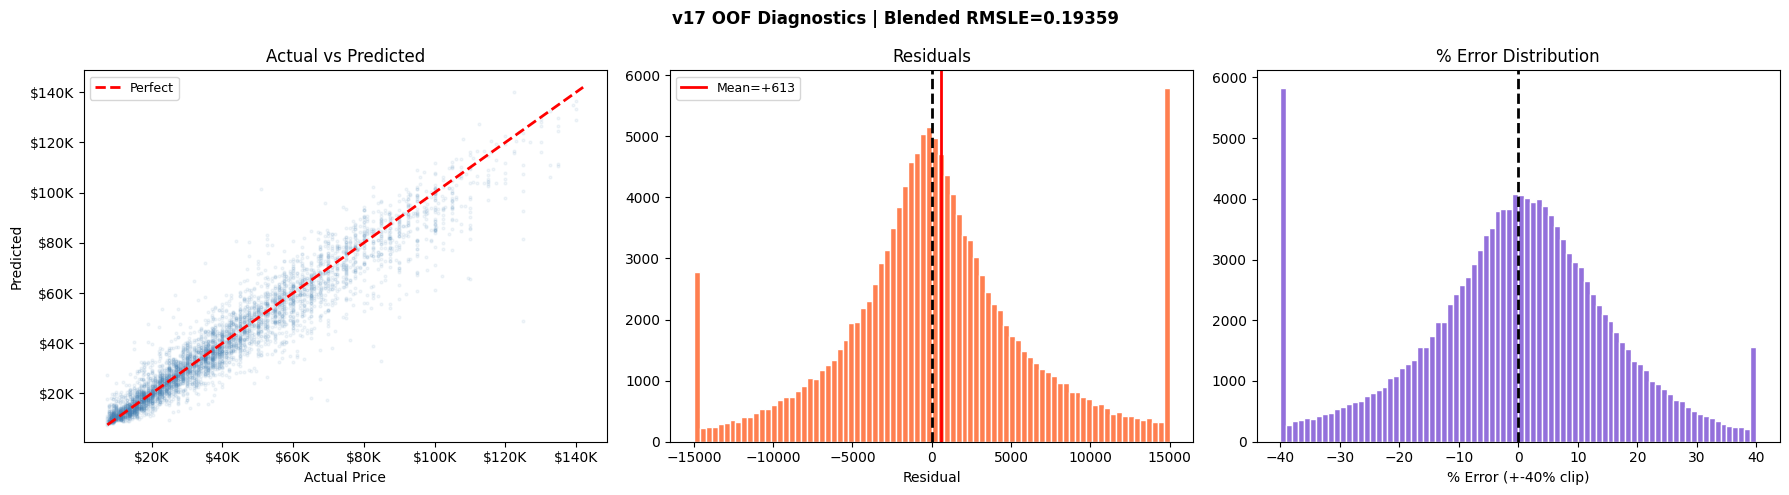

Blended OOF RMSLE : 0.19359
R2                : 0.9155
MAE               : $5,065
Median abs % err  : 9.8%

Top 40 features (LGB1 last fold):
RegionCode                                            103814
MachineAge_rel_ProductConfigID                         95215
ProductConfigID                                        83173
SaleDayOfYear_cos                                      79262
ProductConfigID__x__SaleYear_TE                        76770
SaleDayOfYear_sin                                      76149
SaleDayOfYear                                          71906
MachineAge_rel_Spec_BaseClass                          71842
MachineAge_rel_RegionCode                              69163
SaleDay_sin                                            63398
Spec_BaseClass__x__SaleYear_TE                         63238
FunctionalClassification__x__SaleYear_TE               61082
MachineAge_rel_FunctionalClassification                60761
Spec_SubClass__x__RegionCode_TE                        60375
Regi

In [12]:
oof_blend  = best_w[0]*oof_lgb1 + best_w[1]*oof_lgb2 + best_w[2]*oof_cat
pred_price = np.expm1(oof_blend)
true_price = np.expm1(y_all)
residuals  = true_price - pred_price
pct_err    = (residuals / true_price) * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f'v17 OOF Diagnostics | Blended RMSLE={best_blend:.5f}',
             fontsize=12, fontweight='bold')

idx = np.random.choice(len(true_price), min(5000, len(true_price)), replace=False)
axes[0].scatter(true_price[idx], pred_price[idx], alpha=0.07, s=4, color='steelblue')
mn, mx = true_price.min(), true_price.max()
axes[0].plot([mn, mx], [mn, mx], 'r--', lw=2, label='Perfect')
axes[0].set_xlabel('Actual Price')
axes[0].set_ylabel('Predicted')
axes[0].set_title('Actual vs Predicted')
axes[0].legend(fontsize=9)
fmt = lambda x, _: f'${x/1000:.0f}K'
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(fmt))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(fmt))

axes[1].hist(residuals.clip(-15000, 15000), bins=80, color='coral', edgecolor='white')
axes[1].axvline(0, color='black', lw=2, ls='--')
axes[1].axvline(residuals.mean(), color='red', lw=2, label=f'Mean={residuals.mean():+,.0f}')
axes[1].set_xlabel('Residual')
axes[1].set_title('Residuals')
axes[1].legend(fontsize=9)

axes[2].hist(pct_err.clip(-40, 40), bins=80, color='mediumpurple', edgecolor='white')
axes[2].axvline(0, color='black', lw=2, ls='--')
axes[2].set_xlabel('% Error (+-40% clip)')
axes[2].set_title('% Error Distribution')

plt.tight_layout()
plt.show()

print(f"Blended OOF RMSLE : {best_blend:.5f}")
print(f"R2                : {r2_score(true_price, pred_price):.4f}")
print(f"MAE               : ${np.mean(np.abs(residuals)):,.0f}")
print(f"Median abs % err  : {np.median(np.abs(pct_err)):.1f}%")

fi = pd.Series(lgb1_m.feature_importances_, index=X_tr.columns).sort_values(ascending=False)
print("\nTop 40 features (LGB1 last fold):")
print(fi.head(40).to_string())
